# 07 — Evaluation pitfalls: the research skill

**Goal:** be able to defend a clinical-ML number in front of a skeptical reviewer. AUROC from first principles, PPV vs
prevalence, bootstrap CIs (row vs patient), two kinds of leakage, calibration and prevalence shift.
**Time:** ~3–4 h. **Level:** 3 / 5. **Why this one matters most:** in a medical-AI lab, nobody will ask you to re-derive backprop; they
will ask "was the split by patient?" and "is it calibrated?". Same rules as notebook 00.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(0)

def check(cond, msg):
    assert cond, "❌ " + msg
    print("✅", msg)

## Part 1 — AUROC is a ranking statistic

AUROC = P(score of a random positive > score of a random negative), ties counting ½. That is the Mann–Whitney U
statistic divided by `n₁ n₀`, which can be computed from ranks in O(n log n).

In [2]:
def auc_rank(y, s):
    """AUROC from ranks. y: (n,) in {0,1}, s: (n,) scores. Use scipy.stats.rankdata (average ranks handle ties).
    Hint: sum of positive ranks minus its minimum possible value n1(n1+1)/2, divided by n1*n0."""
    r = rankdata(s)
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

In [3]:
y = rng.integers(0, 2, 500); s = np.round(y * 0.8 + rng.normal(size=500), 1)   # rounding creates ties
check(np.isclose(auc_rank(y, s), roc_auc_score(y, s)), "auc_rank matches sklearn, including ties")
check(np.isclose(auc_rank(y, -s), 1 - auc_rank(y, s)), "flipping the score gives 1 - AUC")
check(np.isclose(auc_rank(y, np.exp(s)), auc_rank(y, s)), "AUC is invariant to monotone transforms")

✅ auc_rank matches sklearn, including ties
✅ flipping the score gives 1 - AUC
✅ AUC is invariant to monotone transforms


**✍️ Predict before running.** Two consequences of `AUC = ranking`: (a) a model whose probabilities are all divided by 10 has which AUC? (b) Can a model with AUROC 0.95 be useless in practice? Give one reason.

> Prediction:
>
> Confidence: [1] / [2] / [3]

## Part 2 — PPV depends on prevalence

A test with 90 % sensitivity and 90 % specificity, used on a population where 1 % have the disease.

**✍️ Predict before running.** Out of the patients the test flags positive, what fraction really have the disease? Give a number before computing.

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [4]:
def ppv(sens, spec, prev):
    """Positive predictive value P(D | +) by Bayes."""
    return sens * prev / (sens * prev + (1 - spec) * (1 - prev))

✅ ppv(0.9, 0.9, 1%)
PPV = 0.083
✅ simulation agrees with Bayes


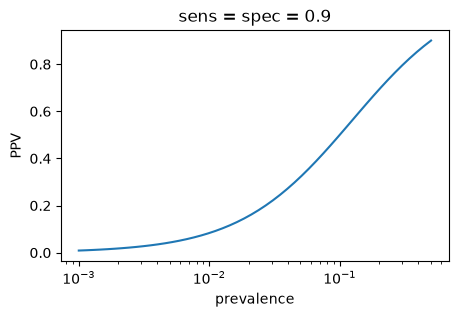

In [5]:
check(np.isclose(ppv(0.9, 0.9, 0.01), 0.009 / (0.009 + 0.099)), "ppv(0.9, 0.9, 1%)")
print(f"PPV = {ppv(0.9, 0.9, 0.01):.3f}")

# simulation: 1M patients
N = 1_000_000
D = rng.random(N) < 0.01
T = np.where(D, rng.random(N) < 0.9, rng.random(N) < 0.1)
check(abs(D[T].mean() - ppv(0.9, 0.9, 0.01)) < 0.005, "simulation agrees with Bayes")

prevs = np.logspace(-3, -0.3, 50)
plt.figure(figsize=(5, 3)); plt.semilogx(prevs, ppv(0.9, 0.9, prevs)); plt.xlabel("prevalence"); plt.ylabel("PPV")
plt.title("sens = spec = 0.9"); plt.show()

## Part 3 — Confidence intervals by bootstrap

A metric on a test set of 300 patients is an estimate with sampling noise. Report it with a CI.

In [6]:
def bootstrap_auc_ci(y, s, n_boot=1000, alpha=0.05, seed=0):
    """Percentile bootstrap CI for AUROC: resample ROWS with replacement n_boot times.
    Skip resamples with a single class. Returns (lo, hi)."""
    r = np.random.default_rng(seed); n = len(y); aucs = []
    for _ in range(n_boot):
        i = r.integers(0, n, n)
        if y[i].min() == y[i].max():
            continue
        aucs.append(auc_rank(y[i], s[i]))
    return tuple(np.quantile(aucs, [alpha / 2, 1 - alpha / 2]))

**✍️ Predict before running.** You go from 200 to 2000 test patients. By what factor does the CI width shrink, roughly?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [7]:
def make_scores(n, seed):
    r = np.random.default_rng(seed); y = r.integers(0, 2, n)
    return y, y + r.normal(0, 1.2, n)

y2, s2 = make_scores(200, 1); y3, s3 = make_scores(2000, 2)
lo2, hi2 = bootstrap_auc_ci(y2, s2); lo3, hi3 = bootstrap_auc_ci(y3, s3)
print(f"n=200 : AUC {auc_rank(y2, s2):.3f} [{lo2:.3f}, {hi2:.3f}]")
print(f"n=2000: AUC {auc_rank(y3, s3):.3f} [{lo3:.3f}, {hi3:.3f}]")
check(lo2 < auc_rank(y2, s2) < hi2, "CI contains the point estimate")
check(2.0 < (hi2 - lo2) / (hi3 - lo3) < 4.5, "width shrinks by about sqrt(10)")

n=200 : AUC 0.740 [0.665, 0.809]
n=2000: AUC 0.702 [0.682, 0.725]
✅ CI contains the point estimate
✅ width shrinks by about sqrt(10)


### Several rows per patient

Medical datasets often have several visits, windows or nights per patient. Rows of the same patient are correlated,
so resampling rows pretends you have more independent information than you do. The **cluster bootstrap** resamples
patients and takes all their rows.

In [8]:
# 60 patients x 20 rows; a patient-level random effect makes rows of the same patient similar
n_pat, k = 60, 20
groups = np.repeat(np.arange(n_pat), k)
u = rng.normal(0, 1.5, n_pat)                               # patient effect
y_c = (rng.random(n_pat * k) < 1 / (1 + np.exp(-u[groups]))).astype(int)
s_c = u[groups] + rng.normal(0, 1, n_pat * k)

def cluster_bootstrap_auc_ci(y, s, groups, n_boot=1000, alpha=0.05, seed=0):
    """Resample GROUPS with replacement; each drawn group contributes all its rows (duplicates allowed)."""
    r = np.random.default_rng(seed); ug = np.unique(groups)
    rows = {g: np.flatnonzero(groups == g) for g in ug}; aucs = []
    for _ in range(n_boot):
        i = np.concatenate([rows[g] for g in r.choice(ug, len(ug), replace=True)])
        if y[i].min() == y[i].max():
            continue
        aucs.append(auc_rank(y[i], s[i]))
    return tuple(np.quantile(aucs, [alpha / 2, 1 - alpha / 2]))

**✍️ Predict before running.** Will the cluster-bootstrap CI be wider or narrower than the row-bootstrap CI here? By a lot or a little?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [9]:
lo_r, hi_r = bootstrap_auc_ci(y_c, s_c); lo_g, hi_g = cluster_bootstrap_auc_ci(y_c, s_c, groups)
print(f"row bootstrap    : [{lo_r:.3f}, {hi_r:.3f}]  width {hi_r - lo_r:.3f}")
print(f"cluster bootstrap: [{lo_g:.3f}, {hi_g:.3f}]  width {hi_g - lo_g:.3f}")
check((hi_g - lo_g) > 1.5 * (hi_r - lo_r), "cluster CI is much wider: rows are not independent")

row bootstrap    : [0.728, 0.782]  width 0.054
cluster bootstrap: [0.697, 0.806]  width 0.109
✅ cluster CI is much wider: rows are not independent


## Part 4 — Leakage

### 4a. Patient leakage through the split

Same structure: 100 patients × 10 visits. Each patient has a 10-dimensional "fingerprint" (think: stable lab values,
demographics) that carries **no causal information** about the outcome, plus 2 weakly informative visit features. The
outcome depends on a hidden patient-level risk.

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict

n_pat, k = 100, 10
g4 = np.repeat(np.arange(n_pat), k)
risk = rng.normal(0, 2, n_pat)
fingerprint = rng.normal(size=(n_pat, 10))[g4] + rng.normal(0, 0.05, (n_pat * k, 10))
visit = rng.normal(size=(n_pat * k, 2))
X4 = np.hstack([fingerprint, visit])
y4 = (rng.random(n_pat * k) < 1 / (1 + np.exp(-(risk[g4] + 0.5 * visit[:, 0])))).astype(int)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=0)

**✍️ Predict before running.** AUROC with a random 5-fold row split vs a 5-fold split by patient (GroupKFold)? Which is the honest one, and what number do you expect for each?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [11]:
p_row = cross_val_predict(rf, X4, y4, cv=KFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
p_grp = cross_val_predict(rf, X4, y4, cv=GroupKFold(5), groups=g4, method="predict_proba")[:, 1]
auc_row, auc_group = roc_auc_score(y4, p_row), roc_auc_score(y4, p_grp)
print(f"row split AUROC  : {auc_row:.3f}\npatient split AUC: {auc_group:.3f}")
check(auc_row - auc_group > 0.1, "the row split is optimistic by more than 0.1 AUROC")

row split AUROC  : 0.810
patient split AUC: 0.541
✅ the row split is optimistic by more than 0.1 AUROC


The model learned *who the patient is*, not *what predicts the outcome*. With a row split, the same patient's other
visits sit in the training fold, so identity → outcome works. On a new patient it does not.

### 4b. Leakage through preprocessing

`n = 100` patients, `p = 5000` features of **pure noise**, labels are coin flips. Any honest AUROC must be ≈ 0.5.

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

Xn = rng.normal(size=(100, 5000)); yn = rng.integers(0, 2, 100)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

**✍️ Predict before running.** You select the 20 features most correlated with y on the full data, then cross-validate a logistic regression on those 20. What AUROC do you get?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [13]:
X_sel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
auc_wrong = cross_val_score(LogisticRegression(max_iter=1000), X_sel, yn, cv=cv, scoring="roc_auc").mean()
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
auc_right = cross_val_score(pipe, Xn, yn, cv=cv, scoring="roc_auc").mean()
print(f"selection outside CV: {auc_wrong:.3f}\nselection inside CV : {auc_right:.3f}")
check(auc_wrong > 0.75, "selecting on the full data invents signal from noise")
check(0.3 < auc_right < 0.7, "selection inside the pipeline gives chance level")

selection outside CV: 0.961
selection inside CV : 0.566
✅ selecting on the full data invents signal from noise
✅ selection inside the pipeline gives chance level


Same trap with scaling, imputation, SMOTE, target encoding, PCA: **anything fitted on data** goes inside the pipeline.

## Part 5 — Calibration

A risk model says "30 %". Among patients who get 30 %, do 30 % have the event? Discrimination (AUROC) and calibration
are different properties.

In [14]:
def reliability_curve(y, p, n_bins=10):
    """Uniform bins on [0, 1]. For each NON-EMPTY bin, return mean predicted p and observed event rate.
    Returns (mean_pred, frac_pos), both 1-D arrays. Put p = 1.0 in the last bin."""
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    keep = [i for i in range(n_bins) if np.any(b == i)]
    return np.array([p[b == i].mean() for i in keep]), np.array([y[b == i].mean() for i in keep])

def brier(y, p):
    """Mean squared error between predicted probability and outcome."""
    return np.mean((p - y) ** 2)

In [15]:
from sklearn.calibration import calibration_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.datasets import make_classification

Xk, yk = make_classification(n_samples=6000, n_features=20, n_informative=4, n_redundant=10, random_state=0)
Xk_tr, Xk_te, yk_tr, yk_te = Xk[:4000], Xk[4000:], yk[:4000], yk[4000:]
p_nb = GaussianNB().fit(Xk_tr, yk_tr).predict_proba(Xk_te)[:, 1]

mp, fp = reliability_curve(yk_te, p_nb)
fp_sk, mp_sk = calibration_curve(yk_te, p_nb, n_bins=10, strategy="uniform")
check(np.allclose(mp, mp_sk) and np.allclose(fp, fp_sk), "reliability_curve matches sklearn")
check(np.isclose(brier(yk_te, p_nb), ((p_nb - yk_te) ** 2).mean()), "brier")

✅ reliability_curve matches sklearn
✅ brier


**✍️ Predict before running.** Naive Bayes assumes features are independent; here 10 of 20 are redundant copies. Will it be over- or under-confident? After isotonic calibration, will AUROC go up, down, or stay the same? Brier?

> Prediction:
>
> Confidence: [1] / [2] / [3]

naive Bayes  AUROC 0.830  Brier 0.199
+ isotonic   AUROC 0.830  Brier 0.168


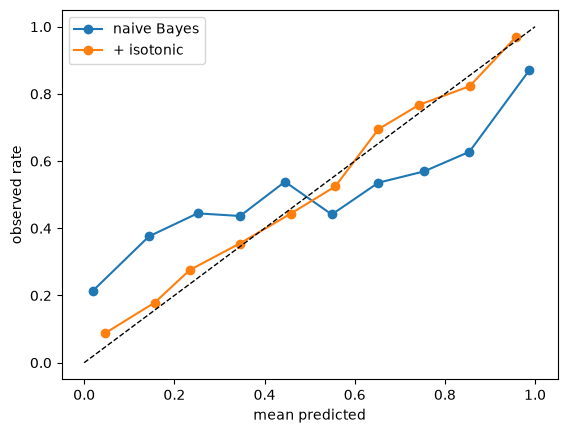

✅ isotonic calibration improves Brier
✅ and barely changes AUROC


In [16]:
p_iso = CalibratedClassifierCV(GaussianNB(), method="isotonic", cv=5).fit(Xk_tr, yk_tr).predict_proba(Xk_te)[:, 1]
for name, p in [("naive Bayes", p_nb), ("+ isotonic", p_iso)]:
    print(f"{name:12s} AUROC {roc_auc_score(yk_te, p):.3f}  Brier {brier(yk_te, p):.3f}")
    plt.plot(*reliability_curve(yk_te, p), "o-", label=name)
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("mean predicted"); plt.ylabel("observed rate"); plt.legend(); plt.show()
check(brier(yk_te, p_iso) < brier(yk_te, p_nb), "isotonic calibration improves Brier")
check(abs(roc_auc_score(yk_te, p_iso) - roc_auc_score(yk_te, p_nb)) < 0.02, "and barely changes AUROC")

### Prevalence shift

A model is trained on a case-control dataset (50 % positives) and deployed in a clinic where prevalence is 5 %.
Its ranking is still fine; its probabilities are not. Under pure prior shift, Bayes gives the correction on the
logit scale: `logit(p') = logit(p) + log(π'/(1−π')) − log(π/(1−π))`.

In [17]:
def simulate(n, prev, seed):
    r = np.random.default_rng(seed); y = (r.random(n) < prev).astype(int)
    X = r.normal(size=(n, 3)) + 1.2 * y[:, None]
    return X, y

X_tr, y_tr = simulate(4000, 0.5, 0); X_dep, y_dep = simulate(20000, 0.05, 1)
p_dep = LogisticRegression().fit(X_tr, y_tr).predict_proba(X_dep)[:, 1]

def prior_shift(p, pi_train, pi_deploy):
    """Correct probabilities for a change in prevalence, on the logit scale."""
    logit = lambda q: np.log(q / (1 - q))
    z = logit(p) + logit(pi_deploy) - logit(pi_train)
    return 1 / (1 + np.exp(-z))

In [18]:
p_fix = prior_shift(p_dep, 0.5, 0.05)
print(f"mean predicted before: {p_dep.mean():.3f} | after: {p_fix.mean():.3f} | true prevalence: {y_dep.mean():.3f}")
check(np.isclose(roc_auc_score(y_dep, p_fix), roc_auc_score(y_dep, p_dep)), "AUROC unchanged (monotone transform)")
check(brier(y_dep, p_fix) < 0.5 * brier(y_dep, p_dep), "Brier more than halved after correction")
check(abs(p_fix.mean() - y_dep.mean()) < 0.01, "mean predicted risk now matches deployment prevalence")

mean predicted before: 0.243 | after: 0.049 | true prevalence: 0.051
✅ AUROC unchanged (monotone transform)
✅ Brier more than halved after correction
✅ mean predicted risk now matches deployment prevalence


## Debrief → `learning/LOG.md`

1. AUROC as a probability, and one case where a high AUROC is clinically useless.
2. PPV at 90/90/1 %, from memory.
3. Why row-level bootstrap and row-level CV are both wrong when patients have several rows.
4. The rule that would have prevented leak 4b, in one sentence.
5. Calibration vs discrimination; what prevalence shift breaks and what it does not.
6. **Still shaky:** list it honestly.